In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model
import matplotlib.dates as mdates
from scipy import stats
import sys
from scipy.stats import norm
from scipy.stats import chi2


data = pd.read_csv("../data/processed/merged_data.csv", index_col=0, parse_dates=True)

In [2]:
# Split in-sample / out-of-sample
train = data[data.index < "2023-01-01"]
test = data[data.index >= "2023-01-01"]

print(f"In-sample : {len(train)} observations")
print(f"Out-of-sample : {len(test)} observations")

# vérif rapide
print(train.index[-1], test.index[0])
print(f"vol train : {train['log_return'].std():.4f}  vol test : {test['log_return'].std():.4f}")
# vol higer in test because of apris 2025 pike

In-sample : 3271 observations
Out-of-sample : 751 observations
2022-12-30 00:00:00 2023-01-03 00:00:00
vol train : 0.0113  vol test : 0.0095


In [3]:
# at first I was trying a rolling refit (751 times) but it ran for 2 hours
# the params don't change enough over that period for it to be worth it
# so we just propagate directly from the estimate to the whole sample
returns_scaled = data["log_return"] * 100
am = arch_model(returns_scaled, vol="GARCH", p=1, q=1, rescale=False)
res_garch = am.fit(disp="off")
garch_var_forecast = res_garch.conditional_volatility**2
garch_var_forecast = garch_var_forecast.loc[test.index]
print(f"Prévisions générées : {len(garch_var_forecast)}")

Prévisions générées : 751


In [4]:
sys.path.append("../src")
from ms_garch2_from_scratch import MSGARCH2

model_ms = MSGARCH2(
    returns=train["log_return"].reset_index(drop=True),
    dates=train.index.to_series().reset_index(drop=True),
    scale=100.0,
    demean=True
)

res_ms = model_ms.fit(n_starts=5, maxiter=1000, random_state=123, verbose=True)
model_ms.summary()

start 01/5 | nll=4151.5991 | success=True


start 02/5 | nll=4151.5991 | success=True


start 03/5 | nll=4151.5991 | success=True


start 04/5 | nll=4151.5991 | success=True


start 05/5 | nll=4151.5991 | success=True


MS-GARCH(2)  nobs=3271  loglik=-4151.60  AIC=8319.20  BIC=8367.94
  success=True
  Regime 1: omega=0.00641  alpha=0.1053  beta=0.8480  unc_var=0.13709
  Regime 2: omega=0.33420  alpha=0.3058  beta=0.6844  unc_var=34.33707
  p11=0.8251  p22=0.2495


In [5]:
# Conditional variance MS-GARCH on full sample
model_ms_full = MSGARCH2(
    returns=data["log_return"].reset_index(drop=True),
    dates=data.index.to_series().reset_index(drop=True),
    scale=100.0,
    demean=True
)

# Reuse parameters estimated in train set
filt = model_ms_full.hamilton_filter(res_ms["params"])

# Cond variance = weighted sum by regim prob
h = filt["h"]
probs = filt["predicted"]
ms_var_forecast = pd.Series(
    (h * probs).sum(axis=1),
    index=data.index
).loc[test.index]

print(f"MS-GARCH variances : {len(ms_var_forecast)} observations")
ms_var_forecast.head()

MS-GARCH variances : 751 observations


Date
2023-01-03    1.195935
2023-01-04    1.042949
2023-01-05    0.966040
2023-01-06    1.047958
2023-01-09    1.636366
dtype: float64

In [6]:
# Realized vol eqiual to square return x 100
realized_var = (test["log_return"] * 100) ** 2

# Mean square error
mse_garch = ((garch_var_forecast - realized_var) ** 2).mean()
mse_ms = ((ms_var_forecast - realized_var) ** 2).mean()

print(f"MSE GARCH(1,1)    : {mse_garch:.4f}")
print(f"MSE MS-GARCH      : {mse_ms:.4f}")

# QLIKE in addition to RMSE (more robust to noisy proxy r^2 cf Patton 2011)
# QLIKE = ln(h) + r^2/h -> we calculate it on the variance at the return scale
def qlike(var_scaled):
    h = var_scaled / 10000            # scale variance toyield
    r2 = (test["log_return"] ** 2)
    return (np.log(h) + r2 / h).mean()

print(f"QLIKE GARCH(1,1)  : {qlike(garch_var_forecast):.4f}")
print(f"QLIKE MS-GARCH    : {qlike(ms_var_forecast):.4f}")

# just to see where the GARCH fails the most
err = (garch_var_forecast - realized_var).abs()
print("\npires dates GARCH:")
print(err.nlargest(5))


MSE GARCH(1,1)    : 12.1938
MSE MS-GARCH      : 12.1090
QLIKE GARCH(1,1)  : -8.5335
QLIKE MS-GARCH    : -8.5340

pires dates GARCH:
Date
2025-04-09    75.379772
2025-04-04    32.994093
2025-04-03    23.601423
2025-04-11    14.245379
2025-04-14    13.951746
dtype: float64


In [7]:
# Mixture VaR for regime-switching models (MS-GARCH) - have a look to mixture notebook
# problem: the predictive density of an MS-GARCH is NOT just a single Gaussian
# with variance = weighted sum of variances 
# its a mix of Gaussians,
# one per regime, weighted by the (smoothed) probability of the regime
# So for VaR, you need to invert the mixture CDF, not just do -z*sqrt(aggregated_var)

# Mixture CDF: F(x) = sum_k pi_k * Phi((x - mu)/sigma_k)
# we're looking for x such that F(x) = alpha -> bisection with brentq
from scipy.optimize import brentq

def mixture_var(h_regimes, probs, alpha, mu=0.0, scale=100.0):
    """Mixed VaR, one day at a time.
            h_regimes: array (T, K) = variances by regime, in units (return*scale)^2
            probs: array (T, K) = predicted probabilities by regime (each row sums to ~1)
            alpha: level (0.01 for 99%, 0.05 for 95%)
            returns an array (T,) of VaR at the return scale (negative values)"""
    h_regimes = np.asarray(h_regimes, dtype=float)
    probs = np.asarray(probs, dtype=float)
    T = len(h_regimes)
    sig = np.sqrt(h_regimes)
    w = probs / probs.sum(axis=1, keepdims=True)

    out = np.empty(T)
    for t in range(T):
        s = sig[t]
        pw = w[t]

        def f(x):
            return np.sum(pw * norm.cdf((x - mu) / s)) - alpha

        lo = mu - 10.0 * s.max()
        while f(lo) > 0:
            lo *= 2.0
        hi = mu
        out[t] = brentq(f, lo, hi, xtol=1e-10)

    return out / scale


def var_single(vol, alpha):
    """Classic Gaussian VaR (for GARCH and GARCH-MIDAS, single density). vol = conditional standard deviation at the return scale"""
    return norm.ppf(alpha) * vol


In [8]:
# Dynamic VaR at 95% and 99%
# GARCH: single density -> classic Gaussian quantile
# MS-GARCH: the predictive density is a MIXTURE of Gaussians (one per regime),
# not a single Gaussian with aggregated variance. Before I used to do -z*sqrt(aggregated_var)
# which crushes the tail on mixed days -> wrong. We invert the CDF of the mixture.
alpha_95 = 0.05
alpha_99 = 0.01

# GARCH VaR (unique density)
garch_vol = np.sqrt(garch_var_forecast) / 100
var_garch_95 = var_single(garch_vol, alpha_95)
var_garch_99 = var_single(garch_vol, alpha_99)

# MS-GARCH VaR (mix) : variances per regime + prob from filter (cell 4)
h_reg = pd.DataFrame(filt["h"], index=data.index).loc[test.index].values
p_reg = pd.DataFrame(filt["predicted"], index=data.index).loc[test.index].values
var_ms_95 = pd.Series(mixture_var(h_reg, p_reg, alpha_95), index=test.index)
var_ms_99 = pd.Series(mixture_var(h_reg, p_reg, alpha_99), index=test.index)

# Violations (return lower than VaR)
returns_test = test["log_return"]

viol_garch_95 = (returns_test< var_garch_95).mean()
viol_garch_99 = (returns_test < var_garch_99).mean()
viol_ms_95 = (returns_test <var_ms_95).mean()
viol_ms_99 = (returns_test < var_ms_99).mean()

print(f"Violation rate GARCH 95% : {viol_garch_95:.4f} (expected : 0.0500)")
print(f"Violation rate GARCH 99% : {viol_garch_99:.4f} (expected : 0.0100)")
print(f"Violation rate MS-GARCH 95% : {viol_ms_95:.4f} (expected: 0.0500)")
print(f"Violation rate MS-GARCH 99% : {viol_ms_99:.4f} (expected: 0.0100)")


Violation rate GARCH 95% : 0.0559 (expected : 0.0500)
Violation rate GARCH 99% : 0.0160 (expected : 0.0100)
Violation rate MS-GARCH 95% : 0.0626 (expected: 0.0500)
Violation rate MS-GARCH 99% : 0.0093 (expected: 0.0100)


In [9]:
def kupiec_test(violations_rate, expected_rate, n_obs):
    T = n_obs
    v = violations_rate
    p = expected_rate
    if v == 0 or v == 1:
        return np.nan, np.nan
    lr = -2 * (np.log((1-p)**(T*(1-v)) * p**(T*v)) - 
               np.log((1-v)**(T*(1-v)) * v**(T*v)))
    pvalue = 1 - chi2.cdf(lr, df=1)
    return lr, pvalue

n = len(test)
print("Kupiec test results:")
for name, viol, alpha in [
    ("GARCH 95%",    viol_garch_95,  0.05),
    ("GARCH 99%",    viol_garch_99,  0.01),
    ("MS-GARCH 95%", viol_ms_95,     0.05),
    ("MS-GARCH 99%", viol_ms_99,     0.01),
]:
    lr, pv = kupiec_test(viol, alpha, n)
    print(f"{name}: LR={lr:.4f}, p-value={pv:.4f}")

Kupiec test results:
GARCH 95%: LR=0.5355, p-value=0.4643
GARCH 99%: LR=2.2953, p-value=0.1298
MS-GARCH 95%: LR=2.3263, p-value=0.1272
MS-GARCH 99%: LR=0.0358, p-value=0.8499


In [10]:
# at first I had forgotten the shift — the violation rates were weird
# (like 8% instead of 5%) because I was comparing VaR(t) with return(t)
# whereas the VaR at t is built from info at t-1
# so shift(1) is mandatory
returns_aligned = returns_test.iloc[1:]
var_garch_95_aligned = var_garch_95.shift(1).dropna()
var_garch_99_aligned = var_garch_99.shift(1).dropna()
var_ms_95_aligned = var_ms_95.shift(1).dropna()
var_ms_99_aligned = var_ms_99.shift(1).dropna()

In [11]:
def christoffersen_test(returns, var_forecast):
    violations = (returns < var_forecast).astype(int).values
    n00 = ((violations[:-1] == 0) & (violations[1:] == 0)).sum()
    n01 = ((violations[:-1] == 0) & (violations[1:] == 1)).sum()
    n10 = ((violations[:-1] == 1) & (violations[1:] == 0)).sum()
    n11 = ((violations[:-1] == 1) & (violations[1:] == 1)).sum()

    pi01 = n01 / max(n00 + n01, 1)
    pi11 = n11 / max(n10 + n11, 1)
    pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1)

    if pi == 0 or pi == 1 or pi01 == 0 or pi11 == 0:
        return np.nan, np.nan

    lr = -2 * (np.log((1-pi)**(n00+n10) * pi**(n01+n11)) -
               np.log((1-pi01)**n00 * pi01**n01 * (1-pi11)**n10 * pi11**n11))
    pvalue = 1 - chi2.cdf(lr, df=1)
    return lr, pvalue

print("Christoffersen test results:")
for name, ret, var in [
    ("GARCH 95%", returns_aligned, var_garch_95_aligned),
    ("GARCH 99%",returns_aligned, var_garch_99_aligned),
    ("MS-GARCH 95%", returns_aligned, var_ms_95_aligned),
    ("MS-GARCH 99%", returns_aligned, var_ms_99_aligned),
]:
    lr, pv = christoffersen_test(ret, var)
    print(f"{name}: LR={lr:.4f}, p-value={pv:.4f}")

Christoffersen test results:
GARCH 95%: LR=0.0175, p-value=0.8948
GARCH 99%: LR=1.7964, p-value=0.1802
MS-GARCH 95%: LR=0.1063, p-value=0.7444
MS-GARCH 99%: LR=3.3118, p-value=0.0688


In [12]:
# Load GARCH-MIDAS forecasts from R
midas_fc = pd.read_csv("../results/midas_oos_forecast.csv")
midas_fc["date"] = pd.to_datetime(midas_fc["date"])
midas_fc = midas_fc.set_index("date")

midas_var_forecast = midas_fc["h_pred"]

# Align with test set
midas_var_forecast = midas_var_forecast.reindex(test.index)

print(f"Previsions MIDAS : {midas_var_forecast.notna().sum()}")
print(midas_var_forecast.head())

# MSE
mse_midas = ((midas_var_forecast - realized_var) ** 2).mean()
print(f"\nMSE GARCH-MIDAS : {mse_midas:.4f}")
print(f"MSE GARCH(1,1)  : {mse_garch:.4f}")
print(f"MSE MS-GARCH    : {mse_ms:.4f}")

Previsions MIDAS : 751
Date
2023-01-03    1.44337
2023-01-04    1.44337
2023-01-05    1.44337
2023-01-06    1.44337
2023-01-09    1.44337
Name: h_pred, dtype: float64

MSE GARCH-MIDAS : 13.0037
MSE GARCH(1,1)  : 12.1938
MSE MS-GARCH    : 12.1090


In [13]:
# VaR GARCH-MIDAS -> single density (no regime), Gaussian quantile = CORRECT, we don't touch it
var_midas_95 = var_single(np.sqrt(midas_var_forecast) / 100, 0.05)
var_midas_99 = var_single(np.sqrt(midas_var_forecast) / 100, 0.01)

# Violation rate
viol_midas_95 = (returns_test < var_midas_95).mean()
viol_midas_99 = (returns_test < var_midas_99).mean()

print(f"Violation MIDAS 95% : {viol_midas_95:.4f} (expected 0.05)")
print(f"Violation MIDAS 99% : {viol_midas_99:.4f} (expected 0.01)")
print(f"QLIKE MIDAS : {qlike(midas_var_forecast):.4f}")

# Kupiec
lr95, pv95 = kupiec_test(viol_midas_95, 0.05, len(test))
lr99, pv99 = kupiec_test(viol_midas_99, 0.01, len(test))
print(f"Kupiec 95% : LR={lr95:.4f}, p={pv95:.4f}")
print(f"Kupiec 99% : LR={lr99:.4f}, p={pv99:.4f}")

# Christoffersen
var_midas_95_al = var_midas_95.shift(1).dropna()
var_midas_99_al = var_midas_99.shift(1).dropna()
ret_al = returns_test.loc[var_midas_95_al.index]

lrc95, pvc95 = christoffersen_test(ret_al, var_midas_95_al)
lrc99, pvc99 = christoffersen_test(ret_al, var_midas_99_al)
print(f"\nChristoffersen 95% : LR={lrc95:.4f}, p={pvc95:.4f}")
print(f"Christoffersen 99% : LR={lrc99:.4f}, p={pvc99:.4f}")


Violation MIDAS 95% : 0.0439 (expected 0.05)
Violation MIDAS 99% : 0.0213 (expected 0.01)
QLIKE MIDAS : -8.4207
Kupiec 95% : LR=0.6040, p=0.4371
Kupiec 99% : LR=7.3206, p=0.0068

Christoffersen 95% : LR=0.1367, p=0.7116
Christoffersen 99% : LR=0.8874, p=0.3462


In [14]:
# Reload everything from the CSVs (standalone cell for the figures + final backtest)
data = pd.read_csv(
    r"../data/processed/merged_data.csv",
    index_col="Date", parse_dates=True
).dropna(subset=["log_return"])

split = pd.Timestamp("2023-01-01")
returns_test = data.loc[split:, "log_return"]

# recalculating the conditional volatility (single density)from arch import arch_model
res_garch = arch_model(data["log_return"]*100, vol="Garch", p=1, q=1, dist="normal", rescale=False).fit(disp="off")
cond_vol = res_garch.conditional_volatility / 100

# MS-GARCH 2: we keep the variances BY REGIME + PREDICTED probabilities (1-step-ahead, not smoothed -> avoids look-ahead bias)
ms2 = pd.read_csv("../results/ms_garch2_probabilities.csv", index_col="Date", parse_dates=True)
ms2 = ms2.reindex(data.index, method="ffill")
h2 = ms2[["h_Regime_1", "h_Regime_2"]].values
p2 = ms2[["predicted_Regime_1", "predicted_Regime_2"]].values
ms2_vol = pd.Series(np.sqrt((h2 * p2).sum(axis=1) / 10000), index=data.index)   # agregate volatility for plots

# MS-GARCH 3 idem, 3 regimes
ms3 = pd.read_csv("../results/ms_garch3_probabilities.csv", index_col="Date", parse_dates=True)
ms3 = ms3.reindex(data.index, method="ffill")
h3 = ms3[["h_Regime_1", "h_Regime_2", "h_Regime_3"]].values
p3 = ms3[["predicted_Regime_1_Calme", "predicted_Regime_2_Modere", "predicted_Regime_3_Turbulent"]].values
ms3_vol = pd.Series(np.sqrt((h3 * p3).sum(axis=1) / 10000), index=data.index)

# GARCH-MIDAS (unique density)
midas = pd.read_csv(
    r"../results/midas_oos_forecast.csv",
    parse_dates=["date"]
).set_index("date")
midas_vol = pd.Series(np.sqrt(midas["h_pred"].values / 10000), index=midas.index)

# VaR
# GARCH & MIDAS: unique density -> Gaussian quantile
var_garch_95 = var_single(cond_vol, 0.05); var_garch_99 = var_single(cond_vol, 0.01)
var_midas_95 = var_single(midas_vol, 0.05); var_midas_99 = var_single(midas_vol, 0.01)

# MS-GARCH(2) and (3): MIXTURE (we invert the mixture CDF, not -z*sqrt(aggregated_var))
var_ms2_95 = pd.Series(mixture_var(h2, p2, 0.05), index=data.index)
var_ms2_99 = pd.Series(mixture_var(h2, p2, 0.01), index=data.index)
var_ms3_95 = pd.Series(mixture_var(h3, p3, 0.05), index=data.index)
var_ms3_99 = pd.Series(mixture_var(h3, p3, 0.01), index=data.index)

print("ok")


ok


In [15]:
# Backtest recap (Table 6 of the report): GARCH & MIDAS single density, MS-GARCH in mixture
def backtest(name, var95, var99, midas=False):
    for cl, var, a in [("95%", var95, 0.05), ("99%", var99, 0.01)]:
        if midas:
            v = var.reindex(returns_test.index)
        else:
            v = var.loc["2023":].shift(1).dropna()
        ret = returns_test.reindex(v.index)
        nv = int((ret < v).sum()); T = len(v.dropna()); rate = nv / T
        lrk, pk = kupiec_test(rate, a, T)
        lrc, pc = christoffersen_test(ret, v)
        print(f"{name:12s} {cl}: {nv}/{T} = {rate*100:.2f}%  Kupiec p={pk:.3f}  Christ p={pc:.3f}")

backtest("GARCH(1,1)", var_garch_95, var_garch_99)
backtest("MS-GARCH(2)", var_ms2_95, var_ms2_99)
backtest("MS-GARCH(3)", var_ms3_95, var_ms3_99)
backtest("GARCH-MIDAS", var_midas_95, var_midas_99, midas=True)


GARCH(1,1)   95%: 37/750 = 4.93%  Kupiec p=0.933  Christ p=0.895
GARCH(1,1)   99%: 12/750 = 1.60%  Kupiec p=0.129  Christ p=0.180
MS-GARCH(2)  95%: 43/750 = 5.73%  Kupiec p=0.367  Christ p=0.744
MS-GARCH(2)  99%: 8/750 = 1.07%  Kupiec p=0.856  Christ p=0.069
MS-GARCH(3)  95%: 38/750 = 5.07%  Kupiec p=0.933  Christ p=0.957
MS-GARCH(3)  99%: 10/750 = 1.33%  Kupiec p=0.383  Christ p=0.117
GARCH-MIDAS  95%: 33/751 = 4.39%  Kupiec p=0.437  Christ p=0.651
GARCH-MIDAS  99%: 16/751 = 2.13%  Kupiec p=0.007  Christ p=0.346


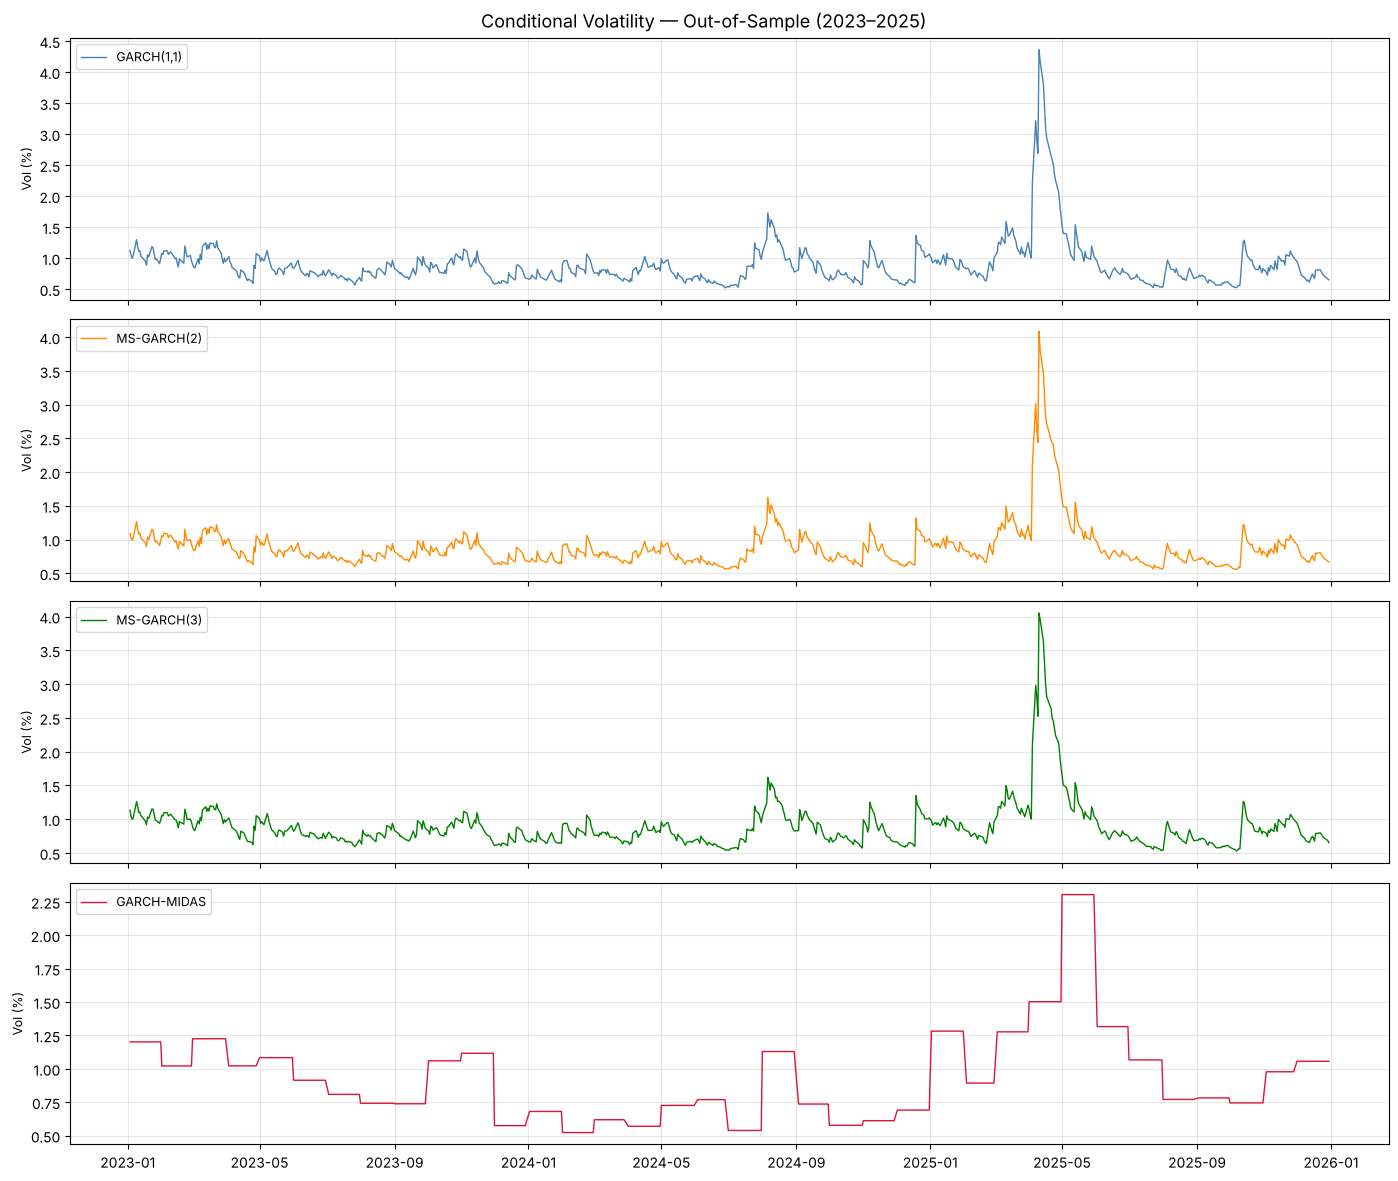

In [16]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
fig.suptitle("Conditional Volatility — Out-of-Sample (2023–2025)", fontsize=13)

models = {
    "GARCH(1,1)": cond_vol.loc["2023":] * 100,
    "MS-GARCH(2)": ms2_vol.loc["2023":] * 100,
    "MS-GARCH(3)": ms3_vol.loc["2023":] * 100,
    "GARCH-MIDAS": midas_vol * 100,
}
colors = ["steelblue", "darkorange", "green", "crimson"]

for ax, (label, vol), color in zip(axes, models.items(), colors):
    ax.plot(vol.index, vol.values, color=color, lw=1.0, label=label)
    ax.set_ylabel("Vol (%)", fontsize=9)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.tight_layout()
plt.savefig("../results/conditional_vol_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

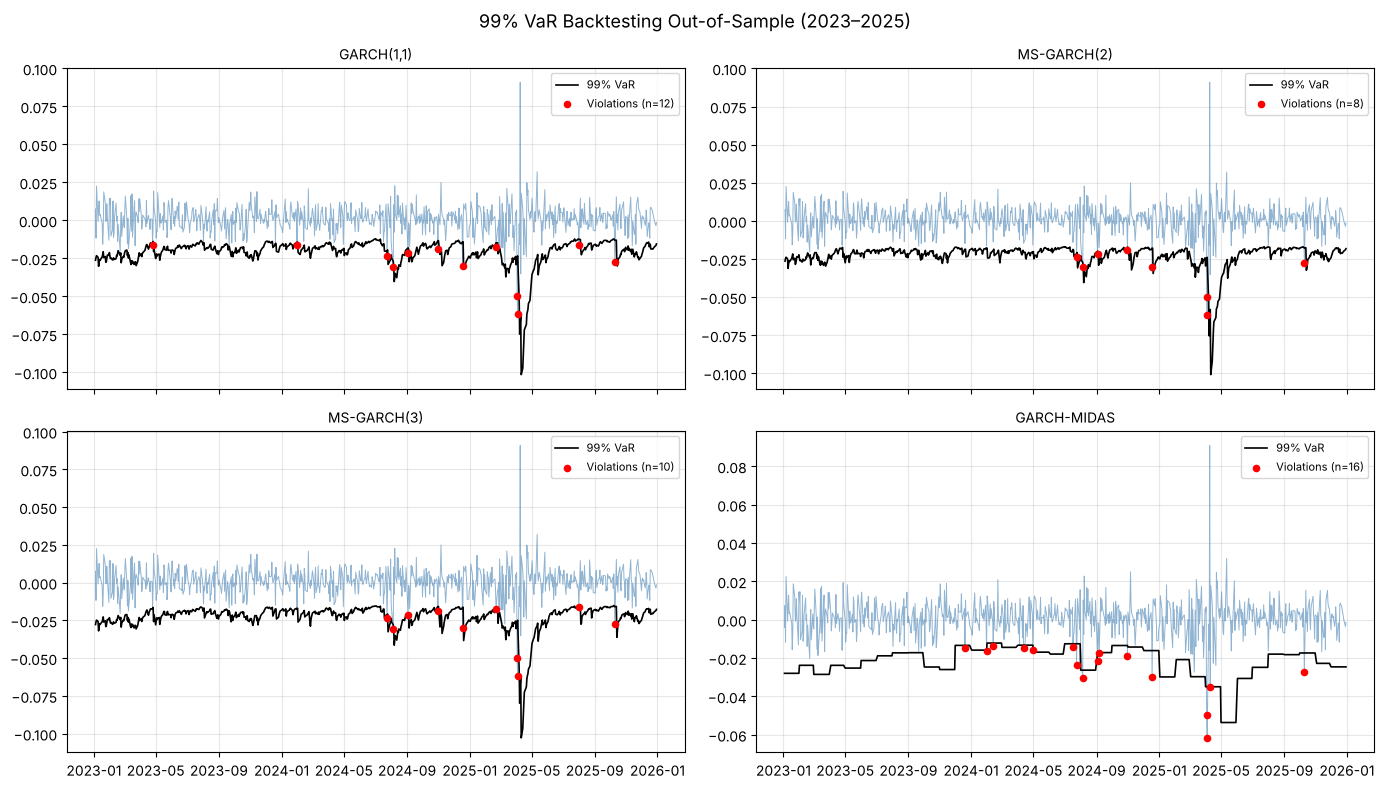

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
fig.suptitle("99% VaR Backtesting Out-of-Sample (2023–2025)", fontsize=13)

for ax, (label, var99) in zip(axes.flat, {
    "GARCH(1,1)": var_garch_99.loc["2023":].shift(1).dropna(),
    "MS-GARCH(2)":var_ms2_99.loc["2023":].shift(1).dropna(),
    "MS-GARCH(3)": var_ms3_99.loc["2023":].shift(1).dropna(),
    "GARCH-MIDAS": var_midas_99,
}.items()):
    ret_aligned = returns_test.reindex(var99.index)
    violations = ret_aligned[ret_aligned < var99]
    ax.plot(ret_aligned.index, ret_aligned.values, color="steelblue", lw=0.7, alpha=0.6)
    ax.plot(var99.index, var99.values, color="black", lw=1.2, label="99% VaR")
    ax.scatter(violations.index, violations.values, color="red", s=20, zorder=5, label=f"Violations (n={len(violations)})")
    ax.set_title(label, fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/var_backtesting_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
    # Combo MS-GARCH-MIDAS "lite" (2 steps) ATTEMPT, not included in the report
    # tau_t (long-term macro of the GARCH-MIDAS) applied as a scaling factor on the
    # short-term variance by regime of the MS-GARCH(2). Result: worse RMSE + VaR rejected,
    # because the regime probabilities are not re-estimated with tau. See §6.1 of the report
import combo_ms_midas_lite
combo_ms_midas_lite.main()


COMBO lite  RMSE = 3.757e-4   QLIKE = -8.6693
(ref: MS-GARCH(2) RMSE~3.26, GARCH-MIDAS RMSE~3.61, GARCH RMSE~3.49)


COMBO 95%: 56/750 = 7.47% Kupiec p = 0.004


COMBO 99%: 20/750 = 2.67% Kupiec p = 0.000

=> conclusion: combo not valid (degraded RMSE + VaR rejected), not retained.


In [19]:
# DM test complet, 2 a 2, sur le test set
# H0 : meme precision (perte quadratique)
# stat < 0 -> modele A meilleur, stat > 0 -> modele B meilleur
from scipy.stats import t as t_dist

returns_test = data.loc["2023-01-01":, "log_return"]
rt2 = returns_test**2

def dm_test_hac(e1, e2, h=1):
    d = e1.values - e2.values
    T = len(d)
    d_bar = d.mean()
    gamma0 = ((d-d_bar)**2).mean()
    # somme des autocov jusqu'a h, Harvey et al 1997
    gammas = [((d[i:]-d_bar)*(d[:-i]-d_bar)).mean() for i in range(1,h+1)]
    var_d = (gamma0 + 2*sum(gammas)) / T
    dm = d_bar / np.sqrt(var_d)
    pv = 2*(1-t_dist.cdf(abs(dm), df=T-1))
    return round(dm,4), round(pv,4)

e_g = (cond_vol.reindex(returns_test.index)**2 - rt2)**2
e_ms2 = (ms2_vol.reindex(returns_test.index)**2 - rt2)**2
e_ms3 = (ms3_vol.reindex(returns_test.index)**2 - rt2)**2
e_mid = (midas_vol.reindex(returns_test.index)**2 - rt2)**2

print("DM test (HAC h=1)")
pairs = [
    ("MS2 vs GARCH", e_ms2, e_g),
    ("MS3 vs GARCH", e_ms3, e_g),
    ("MIDAS vs GARCH", e_mid, e_g),
    ("MS2 vs MIDAS", e_ms2, e_mid),
    ("MS3 vs MIDAS", e_ms3, e_mid),
    ("MS3 vs MS2", e_ms3, e_ms2),
]
for label, ea, eb in pairs:
    dm, pv = dm_test_hac(ea, eb)
    star = "**" if pv<0.05 else ("*" if pv<0.10 else "")
    print(f"{label:15s} DM={dm:7.4f}  p={pv:.4f} {star}")

DM test (HAC h=1)
MS2 vs GARCH    DM=-0.2876  p=0.7738 
MS3 vs GARCH    DM=-0.1065  p=0.9152 
MIDAS vs GARCH  DM= 0.6506  p=0.5155 
MS2 vs MIDAS    DM=-0.9482  p=0.3433 
MS3 vs MIDAS    DM=-0.7790  p=0.4362 
MS3 vs MS2      DM= 0.5615  p=0.5746 
